#Dataset Preliminary Analysis

**Author:** Thor Lemke

The goal of this file is to load the GoEmotions dataset, and verify that the simplified dataset is appropriate for direct usage with machine learning models.

There are several options for acessing the GoEmotions dataset.  One option is to download the raw dataset, available with the following three commands executed within the terminal (verified still works in CoLab via the terminal).



```
wget -P data/full_dataset/ https://storage.googleapis.com/gresearch/goemotions/data/full_dataset/goemotions_1.csv
wget -P data/full_dataset/ https://storage.googleapis.com/gresearch/goemotions/data/full_dataset/goemotions_2.csv
wget -P data/full_dataset/ https://storage.googleapis.com/gresearch/goemotions/data/full_dataset/goemotions_3.csv
```

Alternative options exist via Hugging Face to download both the simplified dataset, with fewer data points and already split into training, validation, and test sets, or the entire raw dataset.  Download of the dataset via Hugging Face is used below for preliminary exploration of the dataset.

In [1]:
# Newer version of matplotlib is required to use the group bar plot
!pip install matplotlib==3.11

In [2]:
from datasets import load_dataset
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Loads the full dataset, raw and simplified, within the pre-determined splits
ds_simplified = load_dataset("google-research-datasets/go_emotions", "simplified")
ds_train = ds_simplified["train"]
ds_validate = ds_simplified["validation"]
ds_test = ds_simplified["test"]

# This only has the one split
ds_raw = load_dataset("google-research-datasets/go_emotions", "raw", split="train")

README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

simplified/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  350kB            

simplified/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

simplified/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  347kB            

... (3 outputs left out)

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

raw/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 24.8MB            

raw/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/211225 [00:00<?, ? examples/s]

In [4]:
# Values pulled directly from GitHub
train_points = 43410
validate_points = 5426
test_points = 5427
total_simp_points = train_points + validate_points + test_points
raw_points = 58009

# Compare number of data points expected versus number loaded from Hugging Face
idSet = set()
idSet.update(ds_train.unique("id"))
idSet.update(ds_test.unique("id"))
idSet.update(ds_validate.unique("id"))
uniqueID_total = len(idSet)
print(f"Number of Simplified Data Points: {ds_train.num_rows + ds_validate.num_rows + ds_test.num_rows}")
print(f"Number of Unique IDs for Raw Data Points: {uniqueID_total}")
print(f"Expected Number of Training Points: {train_points+validate_points+test_points}\n")
# The match in these values verifies that there are no samples in multiple
# splits of the simplified dataset.  By confirming this, we are working to avoid
# data leakage by verifying that no sample will be used in more than one of
# training, validation, and testing.

uniqueID_train = len(ds_train.unique("id"))
print(f"Number of Training Points: {ds_train.num_rows}")
print(f"Number of Unique IDs for Raw Data Points: {uniqueID_train}")
print(f"Expected Number of Training Points: {train_points}\n")

uniqueID_validate = len(ds_validate.unique("id"))
print(f"Number of Validation Points: {ds_validate.num_rows}")
print(f"Number of Unique IDs for Raw Data Points: {uniqueID_validate}")
print(f"Expected Number of Validation Points: {validate_points}\n")

uniqueID_test = len(ds_test.unique("id"))
print(f"Number of Test Points: {ds_test.num_rows}")
print(f"Number of Unique IDs for Raw Data Points: {uniqueID_test}")
print(f"Expected Number of Test Points: {test_points}\n")

# Note here the large discrepeny between the number of raw data points, and the
# the expected number of raw data points based on the reported value in the
# GitHub for the dataset.  Comments were repeated among the different reviewers
# in the raw dataset, but repeats were not counted in the reported total of 58009
# datapoints in the raw dataset.  There is a discrepency between the number of
# unique IDs and anticipated number of data points, which we have not yet resolved,
# but this is only by 2, and with our emphasis on the simplified data for now,
# this is not a situation of high concern.
uniqueID_raw = len(ds_raw.unique("id"))
print(f"Number of Raw Data Points: {ds_raw.num_rows}")
print(f"Number of Unique IDs for Raw Data Points: {uniqueID_raw}")
print(f"Expected Number of Raw Data Points: {raw_points}\n")

Number of Simplified Data Points: 54263
Number of Unique IDs for Raw Data Points: 54263
Expected Number of Training Points: 54263

Number of Training Points: 43410
Number of Unique IDs for Raw Data Points: 43410
Expected Number of Training Points: 43410

Number of Validation Points: 5426
Number of Unique IDs for Raw Data Points: 5426
Expected Number of Validation Points: 5426

Number of Test Points: 5427
Number of Unique IDs for Raw Data Points: 5427
Expected Number of Test Points: 5427

Number of Raw Data Points: 211225
Number of Unique IDs for Raw Data Points: 58011
Expected Number of Raw Data Points: 58009



Percentage of Combined Data Labeled Neutral: 32.8%
Percentage of Training Data Labeled Neutral: 32.8%
Percentage of Validation Data Labeled Neutral: 32.5%
Percentage of Test Data Labeled Neutral: 32.9%


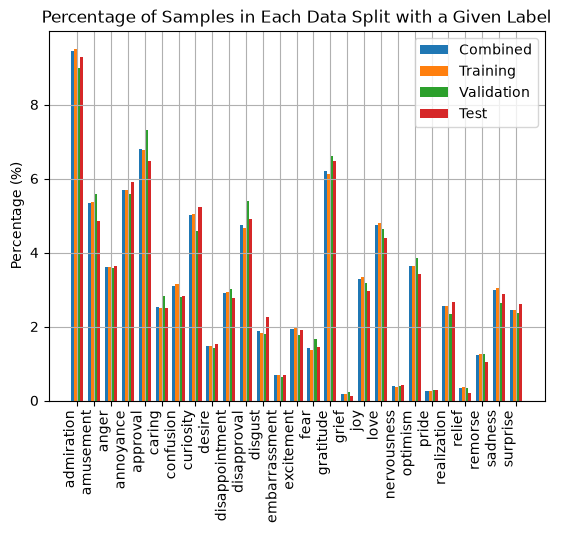

In [5]:
# Loop over the training, validation, and test datasets in the simplified
# subset of data to count the number of times each label was used
# Note that all datapoints do have an associated label, as indicated by the fact
# that the results of this cell do not contain "No label provided for this datapoint"
# This is important for verifying that the simplified dataset is ready for
# use in an ML pipeline.
training_label_tracker = np.zeros((28,))
for label in ds_train['labels']:
  if not label:
    print("No label provided for this datapoint")
  for val in label:
    training_label_tracker[val] += 1

validation_label_tracker = np.zeros((28,))
for label in ds_validate['labels']:
  if not label:
    print("No label provided for this datapoint")
  for val in label:
    validation_label_tracker[val] += 1

test_label_tracker = np.zeros((28,))
for label in ds_test['labels']:
  if not label:
    print("No label provided for this datapoint")
  for val in label:
    test_label_tracker[val] += 1

total_tracker = training_label_tracker + validation_label_tracker + test_label_tracker

# Convert count of appearances for each label to a percentage within the specific
# subset that is being examined (training, validation, test, and all three combined)
# Note that since a single data point can be classified with multiple emotional
# labels, the sum of percentages within a given partition of the data will be
# greater than 100%
total_perc = 100 * total_tracker / total_simp_points
train_perc = 100 * training_label_tracker / train_points
validate_perc = 100 * validation_label_tracker / validate_points
test_perc = 100 * test_label_tracker / test_points

emotion_labels = ['admiration', 'amusement', 'anger', 'annoyance', 'approval',
                  'caring', 'confusion', 'curiosity', 'desire', 'disappointment',
                  'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear',
                  'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism',
                  'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise']

# The percentage of data points in all four categories labeled neutral is
# considerably larger than other labels, so this data is printed out rather
# than included in the plot to avoid skewing the y-axis proportions
print(f"Percentage of Combined Data Labeled Neutral: {total_perc[-1]:.1f}%")
print(f"Percentage of Training Data Labeled Neutral: {train_perc[-1]:.1f}%")
print(f"Percentage of Validation Data Labeled Neutral: {validate_perc[-1]:.1f}%")
print(f"Percentage of Test Data Labeled Neutral: {test_perc[-1]:.1f}%")

# Create a group bar plot showing the percentages for the 27 non-neutral
# emotion labels, across training, test, validation data, as well as the three
# splits combined
fig, ax = plt.subplots()
ax.grouped_bar([total_perc[:-1], train_perc[:-1], validate_perc[:-1], test_perc[:-1]],
                tick_labels=emotion_labels)
ax.set_xticklabels(emotion_labels, rotation=90, ha='right')
plt.grid()
plt.title("Percentage of Samples in Each Data Split with a Given Label")
plt.legend(["Combined", "Training", "Validation", "Test"])
plt.ylabel("Percentage (%)");

# Note that the label percentages are relatively consistent across each
# individual split and the dataset as a whole.  This is important as we want
# the training data to be representative of the dataset as a whole (and similar
# for the validation and test sets).  This results helps to confirm that the
# pre-existing train, validation, test splits are appropriate.